### Machine Learning | Assignment 3 - Evolutionary Algorithms

145873 | Sezer Tetik

#### Exercise 2

In [1]:
import random
import time
from math import comb

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import to_rgba
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

**Setup from Exercise 1.** Each exercise is its own notebook, so the pattern generator from 1a is repeated here unchanged. The pattern size is the one chosen at the end of Exercise 1: **24 bits**, the largest size whose 30 brute-force trials finished within the time budget.

In [2]:
SIZE = 24


def generate_random_pattern(size: int, rng: random.Random) -> str:
    if size < 1:
        raise ValueError("size must be >= 1")

    return format(rng.getrandbits(size), f"0{size}b")

**a)** Fitness of a guess: the number of positions where the guess and the correct pattern have the same bit.

$$f(g, t) = \sum_{i=1}^{n} \mathbb{1}[g_i = t_i] = n - d_H(g, t)$$

where $n$ is the pattern size and $d_H(g, t)$ is the Hamming distance, the number of positions where the two patterns differ.

- **Maximum only at the solution.** $f = n$ exactly when every bit matches, i.e. $g = t$.
- **Decreases with the difference.** Each wrong bit costs exactly 1 point, so fitness falls linearly with the Hamming distance, down to 0 for the complement of the target. Two guesses with the same number of wrong bits score the same, no matter which bits are wrong.
- **Mastermind feedback.** Like the black pegs in Mastermind, it says *how many* bits are right but not *which ones*. The search still has to work out which bits to change.

Brute force in Exercise 1 only used a yes/no check (`guess == target`). That check gives the same answer for all $2^n - 1$ wrong patterns, so a wrong guess carries no hint on where to go next. This fitness ranks every guess by how close it is to the target, which is what the search methods in the next questions rely on.

The fitness is the raw count (an integer from 0 to $n$) rather than the fraction $f/n$, so comparisons between guesses are exact, with no floating-point rounding. Dividing by $n$ gives the normalised version if different sizes ever need to be compared.

In [3]:
def fitness(guess: str, target: str) -> int:
    if len(guess) != len(target):
        raise ValueError("guess and target must have the same size")

    return sum(g == t for g, t in zip(guess, target))

In [4]:
rng = random.Random(0)
target = generate_random_pattern(SIZE, rng)
guess = generate_random_pattern(SIZE, rng)

print(f"target   {target}")
print(f"guess    {guess}")
print(f"matches  {''.join('|' if g == t else ' ' for g, t in zip(guess, target))}")
print(f"fitness  {fitness(guess, target)} / {SIZE}")

target   110110000010110000000111
guess    011000101001111101101111
matches   |   | | |  ||  |  | |||
fitness  11 / 24


**b)** Mutation: `mutate` flips the bit at one position chosen uniformly at random and returns the new pattern. Strings are immutable, so the parent pattern is left untouched.

Hill climbing:

1. Start from a random pattern (`generate_random_pattern`) and compute its fitness.
2. Mutate the current pattern and evaluate the mutant. Keep it only if its fitness is strictly higher, otherwise discard it and keep the current pattern.
3. Stop when the fitness reaches $n$ (the mutant is the solution, since only the solution scores $n$) or after 1000 mutations.

Every mutation is counted, accepted or not. With the fitness from a), one flip always changes the score by exactly $\pm 1$: flipping a wrong bit fixes it ($+1$, accepted), flipping a right bit breaks it ($-1$, rejected). So the climber accepts exactly one mutation per bit that was wrong at the start and rejects all the others.

In [5]:
def mutate(pattern: str, rng: random.Random) -> str:
    i = rng.randrange(len(pattern))
    flipped = "1" if pattern[i] == "0" else "0"

    return pattern[:i] + flipped + pattern[i + 1 :]

In [6]:
MAX_MUTATIONS = 1000


def hill_climbing(target: str, rng: random.Random, max_mutations: int = MAX_MUTATIONS) -> tuple[int, float, bool]:
    size = len(target)
    start = time.perf_counter()

    current = generate_random_pattern(size, rng)
    current_fitness = fitness(current, target)
    mutations = 0

    while current_fitness < size and mutations < max_mutations:
        candidate = mutate(current, rng)
        candidate_fitness = fitness(candidate, target)
        mutations += 1

        if candidate_fitness > current_fitness:
            current, current_fitness = candidate, candidate_fitness

    return mutations, time.perf_counter() - start, current_fitness == size

In [7]:
rng = random.Random(0)
target = generate_random_pattern(SIZE, rng)
mutations, elapsed, solved = hill_climbing(target, rng)

print(f"{SIZE} bits, seed 0: solved = {solved} after {mutations} mutations in {elapsed * 1e3:.2f} ms")

24 bits, seed 0: solved = True after 45 mutations in 0.07 ms


**Expected cost of hill climbing (baseline).** With $k$ wrong bits, a random flip hits a wrong bit with probability $k/n$, so fixing one bit takes $n/k$ mutations on average (geometric distribution). Going from $K$ wrong bits down to 0 therefore costs on average

$$n\left(\frac{1}{K} + \frac{1}{K-1} + \dots + \frac{1}{1}\right) = n\,H_K$$

mutations ($H_K$ is the $K$-th harmonic number; this is the coupon-collector problem). A random start has $K \sim \text{Binomial}(n, 1/2)$ wrong bits, so

$$E[\text{mutations}] = \sum_{k=0}^{n} \binom{n}{k}\, 2^{-n}\; n\,H_k \;\approx\; n\left(\ln\tfrac{n}{2} + 0.58\right)$$

which grows like $n \log n$, against $2^n$ for brute force. Most of these mutations are rejected: only about $n/2$ are accepted, and the last wrong bit alone costs $n$ mutations on average.

**Experiment setup (fair comparison)**

- **Same targets.** Seeds 0–29 as in Exercise 1, with the target as the first draw of each seed. Both methods search for the same 30 targets per size, and brute force reproduces the attempt counts of Exercise 1 exactly.
- **Same sizes.** All sizes of Exercise 1 up to 24 bits (the size chosen there), so the comparison shows how the cost grows and not only a single point.
- **Same unit of work: patterns tried**, i.e. patterns checked against the target. A brute-force attempt is one random pattern. Hill climbing checks its random start plus one pattern per mutation, so patterns tried $= 1 +$ mutations, rejected mutations included. Counting the start also keeps every value $\geq 1$, which a log scale needs (at 2 bits the random start is the solution 1 time in 4, i.e. 0 mutations).
- **Same timing.** `time.perf_counter()` from the first generated pattern until the search stops. Generating the target is excluded for both.

`brute_force` is the function from Exercise 1. The only change is a third return value, `solved` (always `True` for brute force), so both searches return `(count, time, solved)` and run through the same `run_trials`.

In [8]:
SEEDS = list(range(30))
SIZES = [2, 4, 8, 12, 16, 20, 24]


def brute_force(target: str, rng: random.Random) -> tuple[int, float, bool]:
    size = len(target)
    attempts = 0
    start = time.perf_counter()

    while True:
        attempts += 1

        if generate_random_pattern(size, rng) == target:
            return attempts, time.perf_counter() - start, True


def expected_hc_mutations(n: int) -> float:
    return sum(comb(n, k) / 2**n * n * sum(1 / j for j in range(1, k + 1)) for k in range(n + 1))


def run_trials(search, size: int) -> dict:
    counts, times, solved = [], [], []

    for seed in SEEDS:
        rng = random.Random(seed)
        target = generate_random_pattern(size, rng)
        count, elapsed, ok = search(target, rng)

        counts.append(count)
        times.append(elapsed)
        solved.append(ok)

    return {"count": np.array(counts), "time": np.array(times), "solved": np.array(solved)}

In [9]:
METHODS = {"Brute force": brute_force, "Hill climbing": hill_climbing}
results = {method: {} for method in METHODS}

for size in SIZES:
    for method, search in METHODS.items():
        results[method][size] = run_trials(search, size)

    # patterns checked against the target: brute force = attempts, hill climbing = random start + mutations
    results["Brute force"][size]["tried"] = results["Brute force"][size]["count"]
    results["Hill climbing"][size]["tried"] = results["Hill climbing"][size]["count"] + 1

    bf, hc = results["Brute force"][size], results["Hill climbing"][size]
    print(
        f"{size:>2} bits | brute force {bf['time'].sum():7.2f} s"
        f" | hill climbing {hc['time'].sum() * 1e3:5.2f} ms, {hc['solved'].sum()}/{len(SEEDS)} solved"
    )

 2 bits | brute force    0.00 s | hill climbing  0.06 ms, 30/30 solved
 4 bits | brute force    0.00 s | hill climbing  0.14 ms, 30/30 solved
 8 bits | brute force    0.00 s | hill climbing  0.39 ms, 30/30 solved
12 bits | brute force    0.02 s | hill climbing  0.82 ms, 30/30 solved
16 bits | brute force    0.40 s | hill climbing  1.25 ms, 30/30 solved
20 bits | brute force    5.01 s | hill climbing  1.92 ms, 30/30 solved
24 bits | brute force   60.40 s | hill climbing  2.99 ms, 30/30 solved


In [10]:
COLORS = {"Brute force": "#2a78d6", "Hill climbing": "#eb6834"}
MUTED = "#898781"
GRID = "#e1e0d9"
INK = "#52514e"


def grouped_boxplot(metric, title, ylabel, baselines=None, cap=None):
    fig, ax = plt.subplots(figsize=(10, 5.5))
    x = np.arange(len(SIZES))
    handles = []

    for offset, (method, color) in zip([-0.2, 0.2], COLORS.items()):
        positions = x + offset
        fill = to_rgba(color, 0.2)

        ax.boxplot(
            [results[method][s][metric] for s in SIZES],
            positions=positions,
            widths=0.32,
            patch_artist=True,
            showmeans=True,
            boxprops={"facecolor": fill, "edgecolor": color, "linewidth": 1},
            medianprops={"color": color, "linewidth": 2},
            whiskerprops={"color": color, "linewidth": 1},
            capprops={"color": color, "linewidth": 1},
            flierprops={"marker": "o", "markersize": 4, "markerfacecolor": "none", "markeredgecolor": MUTED},
            meanprops={"marker": "D", "markersize": 5, "markerfacecolor": "white", "markeredgecolor": color},
        )
        handles.append(Patch(facecolor=fill, edgecolor=color, label=method))

        if baselines is not None:
            label, values = baselines[method]
            ax.plot(positions, values, color=color, linewidth=1.5, linestyle="--", marker="o", markersize=3, zorder=1)
            handles.append(Line2D([], [], color=color, linewidth=1.5, linestyle="--", label=label))

    if cap is not None:
        ax.axhline(cap, color=MUTED, linewidth=1, linestyle=":", zorder=0)
        handles.append(Line2D([], [], color=MUTED, linewidth=1, linestyle=":", label=f"Hill-climbing cap (1 + {MAX_MUTATIONS} mutations)"))

    handles.append(Line2D([], [], marker="D", linestyle="none", markerfacecolor="white", markeredgecolor=MUTED, label="Mean (box = IQR, line = median, whiskers = 1.5 IQR)"))

    ax.set_yscale("log")
    ax.set_xticks(x, SIZES)
    ax.set_xlabel("Pattern size (bits)")
    ax.set_ylabel(ylabel)
    ax.set_title(title, loc="left")

    ax.grid(axis="y", which="major", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(MUTED)
    ax.tick_params(colors=MUTED, labelcolor=INK)
    ax.legend(handles=handles, frameon=False, loc="upper left")

    plt.show()

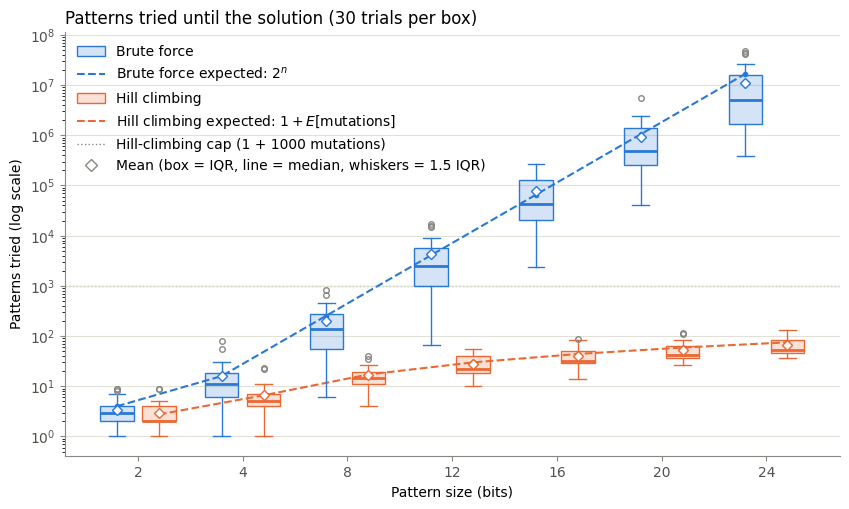

In [11]:
grouped_boxplot(
    "tried",
    title=f"Patterns tried until the solution ({len(SEEDS)} trials per box)",
    ylabel="Patterns tried (log scale)",
    baselines={
        "Brute force": ("Brute force expected: $2^n$", [2**s for s in SIZES]),
        "Hill climbing": ("Hill climbing expected: $1 + E[\\mathrm{mutations}]$", [1 + expected_hc_mutations(s) for s in SIZES]),
    },
    cap=1 + MAX_MUTATIONS,
)

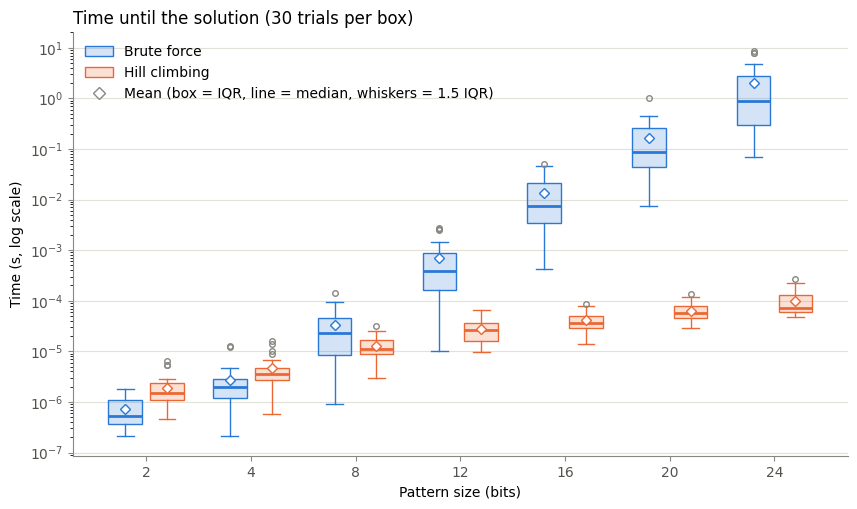

In [12]:
grouped_boxplot(
    "time",
    title=f"Time until the solution ({len(SEEDS)} trials per box)",
    ylabel="Time (s, log scale)",
)

Summary per pattern size. `HC expected` is the theoretical mean number of mutations from above, the `BF / HC` columns say how many times more patterns and time brute force needs, and `µs / pattern` is the cost of trying one pattern (generate + check).

In [13]:
rows = []

for size in SIZES:
    bf, hc = results["Brute force"][size], results["Hill climbing"][size]

    rows.append({
        "bits": size,
        "BF mean attempts": bf["count"].mean(),
        "HC mean mutations": hc["count"].mean(),
        "HC std": hc["count"].std(ddof=1),
        "HC expected": expected_hc_mutations(size),
        "HC max": hc["count"].max(),
        "tried BF / HC": bf["tried"].mean() / hc["tried"].mean(),
        "BF mean time (s)": bf["time"].mean(),
        "HC mean time (s)": hc["time"].mean(),
        "time BF / HC": bf["time"].mean() / hc["time"].mean(),
        "BF µs / pattern": bf["time"].sum() / bf["tried"].sum() * 1e6,
        "HC µs / pattern": hc["time"].sum() / hc["tried"].sum() * 1e6,
        "HC solved": f"{hc['solved'].sum()}/{len(SEEDS)}",
    })

summary = pd.DataFrame(rows).set_index("bits")

pd.set_option("display.float_format", "{:.3g}".format)
summary

,BF mean attempts,HC mean mutations,HC std,HC expected,HC max,tried BF / HC,BF mean time (s),HC mean time (s),time BF / HC,BF µs / pattern,HC µs / pattern,HC solved
bits,,,,,,,,,,,,
2,3.4,1.9,2.02,1.75,8,1.17,7.29e-07,1.87e-06,0.39,0.214,0.645,30/30
4,15.7,5.73,4.94,5.6,22,2.33,2.72e-06,4.71e-06,0.578,0.173,0.7,30/30
8,199,15.4,8.23,16.2,40,12.1,3.29e-05,1.29e-05,2.55,0.165,0.787,30/30
12,4.3e+03,26.8,12.7,28.9,54,155,0.00069,2.73e-05,25.3,0.16,0.979,30/30
16,7.79e+04,38.9,18.7,43,88,1.95e+03,0.0135,4.17e-05,323,0.173,1.05,30/30
20,9.26e+05,50.7,22.6,58.1,113,1.79e+04,0.167,6.38e-05,2.61e+03,0.18,1.23,30/30
24,1.12e+07,64.6,27.3,74,131,1.7e+05,2.01,9.97e-05,2.02e+04,0.18,1.52,30/30


**Discussion**

*Patterns tried.* Brute force reproduces Exercise 1 (same seeds, same attempt counts) and follows $2^n$. Hill climbing follows its own baseline, which grows like $n \log n$: going from 20 to 24 bits adds about 14 mutations (16 expected), while brute force multiplies its attempts by 16. So the gap widens with every size. Brute force needs 1.2× as many patterns as hill climbing at 2 bits, 12× at 8 bits, about 2,000× at 16 bits and about 170,000× at 24 bits (11.2 million attempts against 65 mutations on average). At 24 bits the measured mean (64.6) is below the expected 74. With a standard deviation of 27 mutations, the standard error of a 30-trial mean is about 5, so the gap is about 1.9 standard errors: sampling noise, not a flaw in the model. The smaller sizes sit within about 2 standard errors of the line as well.

*Spread and cap.* The hill-climbing boxes are narrow (24 bits: 36 to 131 mutations, median 52), while brute force spans two orders of magnitude (0.39 to 47 million attempts). Hill climbing varies for two reasons: how many bits are wrong at the start ($\text{Binomial}(n, 1/2)$), and the last few bits. With $k$ wrong bits left, only $k$ of the $n$ possible flips help, so the last bit alone takes $n = 24$ tries on average. Only about 12 mutations are accepted per run at 24 bits (one per bit that was wrong at the start), so around 80% of the mutations are rejected. All 210 hill-climbing runs found the solution, and the longest used 131 mutations, so the 1000-mutation cap never stopped a run. By the formula, the average only reaches 1000 mutations at about 195 bits.

*Time.* Trying one pattern costs 0.27–0.32 µs for brute force (draw random bits and compare strings, both done in C) but 1.0–2.0 µs for hill climbing (build the mutant string, then a Python-level fitness loop over all $n$ bits, so it grows with $n$). Hill climbing pays 3–7× more per pattern. At 2 and 4 bits, where both methods need only a handful of patterns, this makes brute force the faster one in time (time ratio 0.35 and 0.57). Those times are a few microseconds, though, so timer resolution and Python overhead dominate them. From 8 bits on, the number of patterns dominates. At 24 bits brute force takes about 3.1 s per trial on average against about 0.13 ms for hill climbing, roughly 24,000× faster (all 30 trials: about 94 s against 4 ms).

*Why.* Both methods start from random patterns and are measured in the same unit on the same targets, so the difference comes from the feedback each one uses. Brute force only asks "is this the solution?", so a wrong guess tells it nothing. Hill climbing uses the fitness, which says whether a single flip helped, so each mutation tests one bit. The search becomes $n$ independent one-bit problems, solved in $O(n \log n)$ mutations instead of $O(2^n)$ attempts. The remaining waste is that mutation positions are drawn with replacement, so the climber keeps re-trying bits it already knows are right. Avoiding those repeats is the kind of rule a Tabu search can add (Exercise 5).

**c)** A *local maximum* is a pattern where no neighbour has a strictly higher fitness. Here the neighbours are the $n$ patterns that differ from it in one bit, which is what `mutate` can reach. If the hill climber reaches a local maximum that is not the solution, every mutation from then on is rejected and it is stuck until the budget runs out.

**With this fitness and this mutation, there are no local maxima other than the solution.** Take any pattern $g \neq t$. It has at least one wrong bit, and flipping that bit gives fitness $f(g) + 1$, so $g$ always has a strictly better neighbour. The solution is the only pattern without one. Each bit adds to the fitness on its own (the fitness is a sum over positions), so fixing one bit never depends on the others. The landscape has a single peak, like the classic *OneMax* problem.

It also has no plateaus. A flip always changes the fitness by exactly $\pm 1$, never 0, so a pattern never has a neighbour with equal fitness. Since only $+1$ moves are accepted, a bit that is right stays right, and every accepted mutation brings the climber one bit closer. The only way the hill climber can stop without the solution is the 1000-mutation cap.

The three checks below back this up:

1. **Exhaustive search, 16 bits.** Go through all $2^{16} = 65{,}536$ patterns of a 16-bit problem and all their neighbours. The solution should be the only local maximum, and every pattern should have exactly one improving flip per wrong bit. 24 bits would mean $2^{24} \cdot 24 \approx 400$ million fitness evaluations, too slow in Python, and the argument above does not depend on $n$.
2. **The 30 runs at 24 bits.** Plot the fitness after every mutation. No run should get stuck below the maximum.
3. **The cap.** Compute exactly how likely hill climbing is to run out of mutations before reaching the solution.

In [14]:
n = 16
target = generate_random_pattern(n, random.Random(0))
local_maxima = []
changes = set()

for value in range(2**n):
    pattern = format(value, f"0{n}b")
    current_fitness = fitness(pattern, target)
    better = 0

    for i in range(n):
        neighbour = pattern[:i] + ("1" if pattern[i] == "0" else "0") + pattern[i + 1 :]
        change = fitness(neighbour, target) - current_fitness
        changes.add(change)
        better += change > 0

    assert better == n - current_fitness  # one improving flip per wrong bit

    if better == 0:
        local_maxima.append(pattern)

print(f"{2**n} patterns, fitness changes seen for one flip: {sorted(changes)}")
print(f"local maxima: {local_maxima} (target {target})")

65536 patterns, fitness changes seen for one flip: [-1, 1]
local maxima: ['1101100000101100'] (target 1101100000101100)


`hill_climbing_trace` is the same loop as `hill_climbing`, but it records the fitness after every mutation instead of timing the run. It uses the random generator in exactly the same order, so with the same seeds it replays the 30 runs of b) at 24 bits.

Dashed line: the expected fitness after $m$ mutations. With $k$ wrong bits, a mutation fixes one with probability $k/n$, so the expected number of wrong bits shrinks by a factor $(1 - 1/n)$ per mutation. Starting from $n/2$ wrong bits on average, that gives $E[f_m] = n - \frac{n}{2}\left(1 - \frac{1}{n}\right)^m$.

In [15]:
def hill_climbing_trace(target: str, rng: random.Random, max_mutations: int = MAX_MUTATIONS) -> list[int]:
    size = len(target)
    current = generate_random_pattern(size, rng)
    trace = [fitness(current, target)]

    while trace[-1] < size and len(trace) - 1 < max_mutations:
        candidate = mutate(current, rng)
        candidate_fitness = fitness(candidate, target)

        if candidate_fitness > trace[-1]:
            current = candidate
            trace.append(candidate_fitness)
        else:
            trace.append(trace[-1])

    return trace


traces = []

for seed in SEEDS:
    rng = random.Random(seed)
    target = generate_random_pattern(SIZE, rng)
    traces.append(hill_climbing_trace(target, rng))

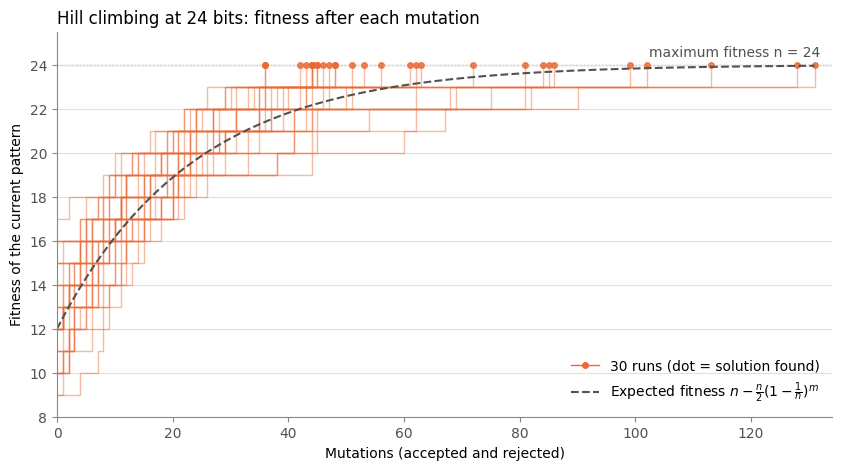

In [16]:
HC_COLOR = COLORS["Hill climbing"]

fig, ax = plt.subplots(figsize=(10, 5))

for t in traces:
    ax.plot(range(len(t)), t, drawstyle="steps-post", color=HC_COLOR, linewidth=1, alpha=0.45)
    ax.plot(len(t) - 1, t[-1], marker="o", markersize=4, color=HC_COLOR, alpha=0.8, linestyle="none")

longest = max(len(t) for t in traces)
m = np.arange(longest)
ax.plot(m, SIZE - SIZE / 2 * (1 - 1 / SIZE) ** m, color=INK, linewidth=1.5, linestyle="--")
ax.axhline(SIZE, color=MUTED, linewidth=1, linestyle=":", zorder=0)

ax.annotate(f"maximum fitness n = {SIZE}", xy=(longest, SIZE), xytext=(0, 6), textcoords="offset points", ha="right", color=INK)

handles = [
    Line2D([], [], color=HC_COLOR, linewidth=1, marker="o", markersize=4, label=f"{len(SEEDS)} runs (dot = solution found)"),
    Line2D([], [], color=INK, linewidth=1.5, linestyle="--", label="Expected fitness $n - \\frac{n}{2}(1 - \\frac{1}{n})^m$"),
]
ax.legend(handles=handles, frameon=False, loc="lower right")

ax.set_xlim(0, longest + 2)
ax.set_ylim(min(t[0] for t in traces) - 1, SIZE + 1.5)
ax.set_xlabel("Mutations (accepted and rejected)")
ax.set_ylabel("Fitness of the current pattern")
ax.set_title(f"Hill climbing at {SIZE} bits: fitness after each mutation", loc="left")

ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color(MUTED)
ax.tick_params(colors=MUTED, labelcolor=INK)

plt.show()

**Probability of hitting the cap.** The number of wrong bits $k$ is a Markov chain: each mutation lowers it by one with probability $k/n$ and leaves it unchanged otherwise, starting from $k \sim \text{Binomial}(n, 1/2)$. Pushing that distribution forward 1000 mutations gives the exact probability that wrong bits are still left when the cap is reached. The remaining mass is summed directly instead of computing $1 - P(k = 0)$, because the result is far below double-precision rounding.

In [17]:
def prob_unsolved(n: int, mutations: int = MAX_MUTATIONS) -> float:
    k = np.arange(n + 1)
    p = np.array([comb(n, i) / 2**n for i in k])  # p[k] = P(k wrong bits)

    for _ in range(mutations):
        fixed = p * k / n  # probability mass that fixes one bit: k -> k - 1
        p = p - fixed
        p[:-1] += fixed[1:]

    return p[1:].sum()


for n in [SIZE, 100, 150, 200, 300]:
    print(f"{n:>3} bits: P(still unsolved after {MAX_MUTATIONS} mutations) = {prob_unsolved(n):.2g}")

 24 bits: P(still unsolved after 1000 mutations) = 3.9e-18
100 bits: P(still unsolved after 1000 mutations) = 0.0022
150 bits: P(still unsolved after 1000 mutations) = 0.089
200 bits: P(still unsolved after 1000 mutations) = 0.49
300 bits: P(still unsolved after 1000 mutations) = 1


**Answer and discussion**

*No local maxima.* The exhaustive 16-bit check finds exactly one pattern without a better neighbour: the solution. Every one of the 65,536 patterns has exactly one improving flip per wrong bit. A flip only ever changes the fitness by $-1$ or $+1$, so there are no plateaus either. This is what the argument above predicts for every $n$.

*The runs.* All 30 traces at 24 bits climb in steps of $+1$ and end at 24. None of them levels off below the maximum. The flat stretches are rejected mutations, not plateaus in the landscape: the current pattern still has $k$ better neighbours, and the climber just has not drawn one of them yet. They get longer towards the end because only $k$ of the $n$ flips help (with one wrong bit left, 1 in 24), and the expected curve flattens the same way as it approaches $n$. That is why some runs need over 100 mutations: they spend most of them waiting for the last one or two bits.

*The cap.* The chance that a 24-bit run is still unsolved after 1000 mutations is about $4 \cdot 10^{-18}$, so the cap does not matter here (the longest run in b) used 131). It only starts to matter for much larger patterns: 0.2% at 100 bits, 9% at 150 bits, about 50% at 200 bits and practically certain at 300 bits. Even then the climber is not stuck. It is still going up and would finish with a bigger budget.

*When local maxima would appear.* The guarantee comes from this fitness together with the one-bit neighbourhood, not from hill climbing itself. With the yes/no feedback of Exercise 1 (fitness 1 for the solution, 0 otherwise), every pattern more than one flip away from the solution has no better neighbour. A strict hill climber would never leave its starting pattern. Fitness functions where bits interact, for example where a group of bits only scores when all of them are right (deceptive "trap" functions), do create local maxima. The fitness for the variable-length problem in Exercise 4 will need the same check.

**So for this problem, no: the hill climber cannot get stuck on a local maximum. The only thing that can stop it early is the mutation budget, and at 24 bits that practically never happens.**